# Лабораторна робота № 8
## Просторова фільтрація зображень: згладжування, шумозаглушення та підкреслення меж

**Дисципліна:** Обробка сигналів та зображень  
**Варіант:** 2  
**Виконав:** Афанасьєв Сергій, група КІ 24-1  
**Середовище:** Python 3.10+, NumPy, OpenCV (`cv2`), SciPy (`scipy.ndimage`), Matplotlib

## 1. Мета роботи

Вивчити двовимірну просторову фільтрацію через згортку та кореляцію з маскою, порівняти лінійні (усереднювальний Box і Гаусів) та нелінійні (медіанний і білатеральний) фільтри для гаусового та імпульсного шумів, виконати підвищення різкості оператором Лапласа та оцінити якість відновлення за метриками MSE і PSNR.

## 2. Основні співвідношення

- Згортка (кореляція) з маскою $K \times K$, $K = 2a + 1$: вихідний піксель є зваженою сумою пікселів околиці. Для симетричної маски згортка та кореляція збігаються, для несиметричної — ні (маска при згортці перевертається).
- Box-фільтр: усі ваги дорівнюють $1 / K^2$. Гаусів фільтр: ядро $w(x, y) \propto \exp\left(-\dfrac{x^2 + y^2}{2\sigma^2}\right)$, нормоване на суму 1; не дає паразитних смуг на перепадах яскравості.
- Медіанний фільтр — нелінійний ранговий: вихід дорівнює медіані значень околиці, тому поодинокі викиди (імпульсні точки) зникають.
- Білатеральний фільтр: вага пікселя — добуток просторової ваги ($\sigma_s$) та фотометричної ваги за різницею яскравостей ($\sigma_c$); однорідні ділянки згладжуються, межі зберігаються.
- Оператор Лапласа (8-зв'язне ядро з центром $+8$) та підвищення різкості $I_{sharp} = I + k \nabla^2 I$, $k > 0$.
- Метрики: $\mathrm{MSE} = \dfrac{1}{MN} \sum (I_{ref} - I_{proc})^2$, $\mathrm{PSNR} = 10 \lg \dfrac{255^2}{\mathrm{MSE}}$, дБ.

## 3. Індивідуальне завдання (варіант 2)

| $\sigma_g$ | $p_{sp}$ | $K_{box}$, $K_G$, $K_{med}$ | $\sigma$ Гауса | Bilateral $(d, \sigma_c, \sigma_s)$ | $k_{sharp}$ |
|---|---|---|---|---|---|
| 25.0 | 0.08 | 5×5, 5×5, 5 | 1.5 | $d = 9$, $\sigma_c = 80$, $\sigma_s = 80$ | 0.60 |

На сторінці лабораторної в еталонному скрипті використано фіксовані значення $\sigma_c = \sigma_s = 75$, а не параметри варіанта. У моїй роботі використано параметри варіанта 2 ($\sigma_c = \sigma_s = 80$), тому числа в таблиці MSE / PSNR відрізняються від наведених на сторінці прикладу.

Аналітичний розрахунок:

- Box $5 \times 5$: вага кожного відліку $1 / 25 = 0.04$; у плоских областях дисперсія гаусового шуму зменшується в 25 разів;
- Гаусове ядро $5 \times 5$, $\sigma = 1.5$: одновимірні ваги $\propto 1;\ 0.8007;\ 0.4111$ (для $x = 0, \pm 1, \pm 2$), сума $3.4236$, тому центральний коефіцієнт $0.2921^2 = 0.0853$; сума квадратів ваг $0.0500$, дисперсія шуму в плоских областях зменшується приблизно у 20 разів;
- очікуване MSE гаусового шуму без відсікання $\sigma_g^2 = 625$; сума коефіцієнтів ядра Лапласа дорівнює нулю, тому однорідні ділянки підвищення різкості не змінює; при $k = 0.60$ центральний коефіцієнт сумарного ядра $1 + 0.6 \cdot 8 = 5.8$, сусідні — $-0.6$;
- імпульсний шум: частка змінених пікселів $\approx p_{sp} = 8\ \%$ (половина «сіль», половина «перець»).

Вихідне зображення (еталонна сцена $400 \times 600$ з прямокутником, концентричними колами, штрихами, променями та текстом) генерується в коді; шум відтворюється завдяки `np.random.seed(42)`.

## 4. Хід виконання

Код розбито на блоки, повний скрипт знаходиться у файлі `lab8_spatial_filters.py`. Графіки зберігаються в каталог `figures/`, еталонне зображення — у `data/`.

### Блок 1. Підготовка середовища, імпорт та генерація еталонної сцени

In [1]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
from scipy import ndimage

# каталоги для графіків і даних
os.makedirs("figures", exist_ok=True)
os.makedirs("data", exist_ok=True)

plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#333333'
plt.rcParams['axes.linewidth'] = 1.0
plt.rcParams['grid.color'] = '#cccccc'
plt.rcParams['grid.linestyle'] = '--'
plt.rcParams['grid.alpha'] = 0.6

# параметри варіанта 2
SIGMA_G = 25.0            # СКВ адитивного гаусового шуму
P_SP = 0.08               # щільність шуму "сіль та перець"
K_BOX = 5                 # ядро Box-фільтра 5x5
K_GAUSS, SIGMA = 5, 1.5   # ядро Гауса 5x5 та його sigma
K_MED = 5                 # апертура медіанного фільтра
BIL_D, BIL_SC, BIL_SS = 9, 80, 80   # білатеральний фільтр: d, sigma_color, sigma_space
K_SHARP = 0.60            # вага підвищення різкості


def generate_reference_scene(height=400, width=600):
    """
    Еталонна сцена з контрастними фігурами, тонкими лініями та текстом:
    прямокутник, концентричні кола, штрихи, промені й напис.
    """
    img = np.full((height, width), 60, dtype=np.uint8)
    cv2.rectangle(img, (40, 40), (240, 180), 200, -1)
    cv2.rectangle(img, (40, 40), (240, 180), 255, 2)
    for r, col in [(90, 230), (70, 90), (50, 210), (30, 110), (12, 250)]:
        cv2.circle(img, (430, 120), r, col, -1)
    for i in range(8):                                    # вертикальні штрихи
        x = 50 + i * 12
        cv2.line(img, (x, 220), (x, 330), 255 if i % 2 == 0 else 120, 2)
    for ang in range(0, 180, 15):                         # промені з одного центру
        a = np.deg2rad(ang)
        p1 = (int(190 + 90 * np.cos(a)), int(290 + 90 * np.sin(a)))
        p2 = (int(190 - 90 * np.cos(a)), int(290 - 90 * np.sin(a)))
        cv2.line(img, p1, p2, 190, 1)
    cv2.putText(img, "FILTER 8", (330, 290), cv2.FONT_HERSHEY_SIMPLEX, 1.4, 255, 3)
    cv2.putText(img, "Spatial", (340, 345), cv2.FONT_HERSHEY_SIMPLEX, 0.9, 170, 2)
    cv2.line(img, (330, 365), (570, 365), 255, 1)
    return img


reference = generate_reference_scene()
cv2.imwrite("data/reference_pattern.png", reference)
print("Еталонну сцену збережено: data/reference_pattern.png")

Еталонну сцену збережено: data/reference_pattern.png


### Блок 2. Моделі шумів та метрики якості (MSE, PSNR)

--- МОДЕЛІ ШУМІВ ---
Гаусів шум (sigma = 25.0): MSE = 601.41, PSNR = 20.34 дБ (теоретично MSE ~ sigma^2 = 625, менше через відсікання)
Шум 'сіль та перець' (p = 0.08): MSE = 1691.95, PSNR = 15.85 дБ, змінено 7.85 % пікселів


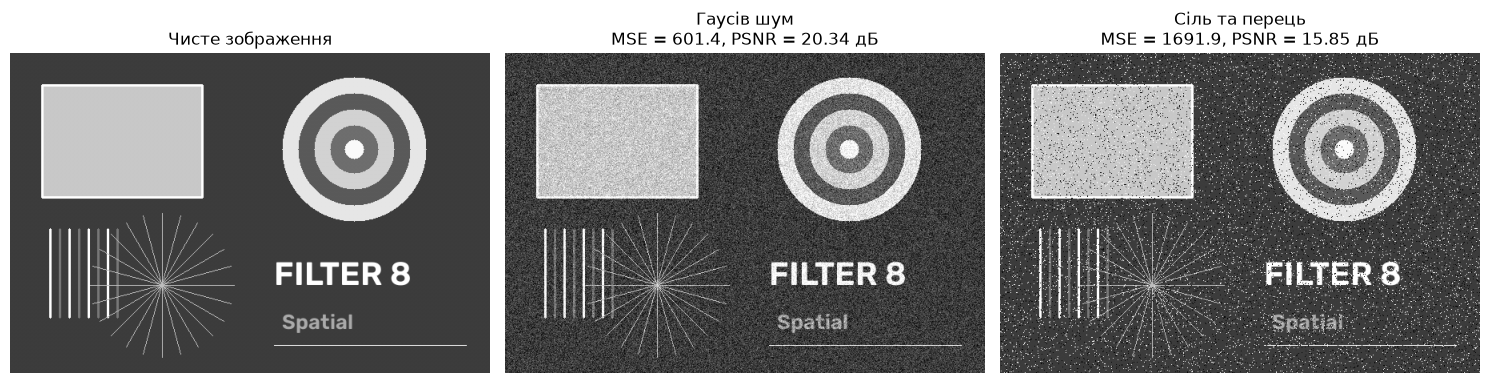

In [2]:
def add_gaussian_noise(image, sigma=SIGMA_G):
    """Адитивний гаусів шум N(0, sigma^2) з відсіканням до [0, 255]."""
    noise = np.random.normal(0, sigma, image.shape)
    return np.clip(image.astype(np.float64) + noise, 0, 255).astype(np.uint8)


def add_salt_and_pepper_noise(image, prop=P_SP):
    """Імпульсний шум: частка prop пікселів стає 255 (сіль) або 0 (перець)."""
    noisy = image.copy()
    rnd = np.random.random(image.shape)
    noisy[rnd < prop / 2] = 0
    noisy[(rnd >= prop / 2) & (rnd < prop)] = 255
    return noisy


def calculate_metrics(ref_img, proc_img):
    """MSE та PSNR (дБ) відносно еталона."""
    mse = np.mean((ref_img.astype(np.float64) - proc_img.astype(np.float64)) ** 2)
    psnr = 10 * np.log10(255.0 ** 2 / mse) if mse > 0 else float('inf')
    return mse, psnr


np.random.seed(42)
noisy_g = add_gaussian_noise(reference)
noisy_sp = add_salt_and_pepper_noise(reference)

mse_g, psnr_g = calculate_metrics(reference, noisy_g)
mse_sp, psnr_sp = calculate_metrics(reference, noisy_sp)
share_sp = 100 * np.mean(noisy_sp != reference)

print("--- МОДЕЛІ ШУМІВ ---")
print(f"Гаусів шум (sigma = {SIGMA_G}): MSE = {mse_g:.2f}, PSNR = {psnr_g:.2f} дБ "
      f"(теоретично MSE ~ sigma^2 = {SIGMA_G ** 2:.0f}, менше через відсікання)")
print(f"Шум 'сіль та перець' (p = {P_SP}): MSE = {mse_sp:.2f}, PSNR = {psnr_sp:.2f} дБ, "
      f"змінено {share_sp:.2f} % пікселів")

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, a, title in [(axes[0], reference, "Чисте зображення"),
                     (axes[1], noisy_g, f"Гаусів шум\nMSE = {mse_g:.1f}, PSNR = {psnr_g:.2f} дБ"),
                     (axes[2], noisy_sp, f"Сіль та перець\nMSE = {mse_sp:.1f}, PSNR = {psnr_sp:.2f} дБ")]:
    ax.imshow(a, cmap='gray', vmin=0, vmax=255)
    ax.set_title(title)
    ax.axis('off')
plt.tight_layout()
plt.savefig("figures/noise_models_comparison.png", dpi=300)
plt.show()

**Результати моделювання шумів:**

| Шум | Параметр | MSE | PSNR, дБ |
|---|---|---|---|
| Гаусів | $\sigma_g = 25$ | 601.43 | 20.34 |
| «Сіль та перець» | $p_{sp} = 0.08$ | 1691.60 | 15.85 |

Для гаусового шуму MSE (601.43) трохи менше за теоретичні $\sigma_g^2 = 625$, бо значення, що виходять за межі $[0, 255]$, відсікаються. Для шуму «сіль та перець» змінено 7.85 % пікселів, що відповідає $p_{sp} = 8\ \%$ з похибкою вибірки; MSE майже втричі більше (1691.60), бо кожен імпульс — це найбільший можливий викид ($255$ або $0$ на тлі 60–255), тоді як гаусів шум має обмежену амплітуду.

### Блок 3. Шумозаглушення: Box, Gauss, Median, Bilateral


--- ПЕРЕВІРКА ЗГОРТКИ ТА КОРЕЛЯЦІЇ ---
max|cv2.blur - ndimage.convolve| для Box 5x5 = 0.48 рівня (різниця від округлення до uint8)
Для несиметричного ядра max|згортка - кореляція| = 83.57; для симетричних ядер Box та Gauss вони збігаються

--- ТАБЛИЦЯ MSE ТА PSNR ---
Фільтр                   Гаус: MSE  Гаус: PSNR, дБ    S&P: MSE   S&P: PSNR, дБ
Без обробки                 601.41           20.34     1691.95           15.85
Box (5x5)                   374.47           22.40      453.25           21.57
Gauss (5x5, s=1.5)          299.58           23.37      388.87           22.23
Median (5)                  241.27           24.31      218.59           24.73
Bilateral (d=9)             106.09           27.87      612.87           20.26
Найкращий фільтр для гаусового шуму: Bilateral; для імпульсного шуму: Median


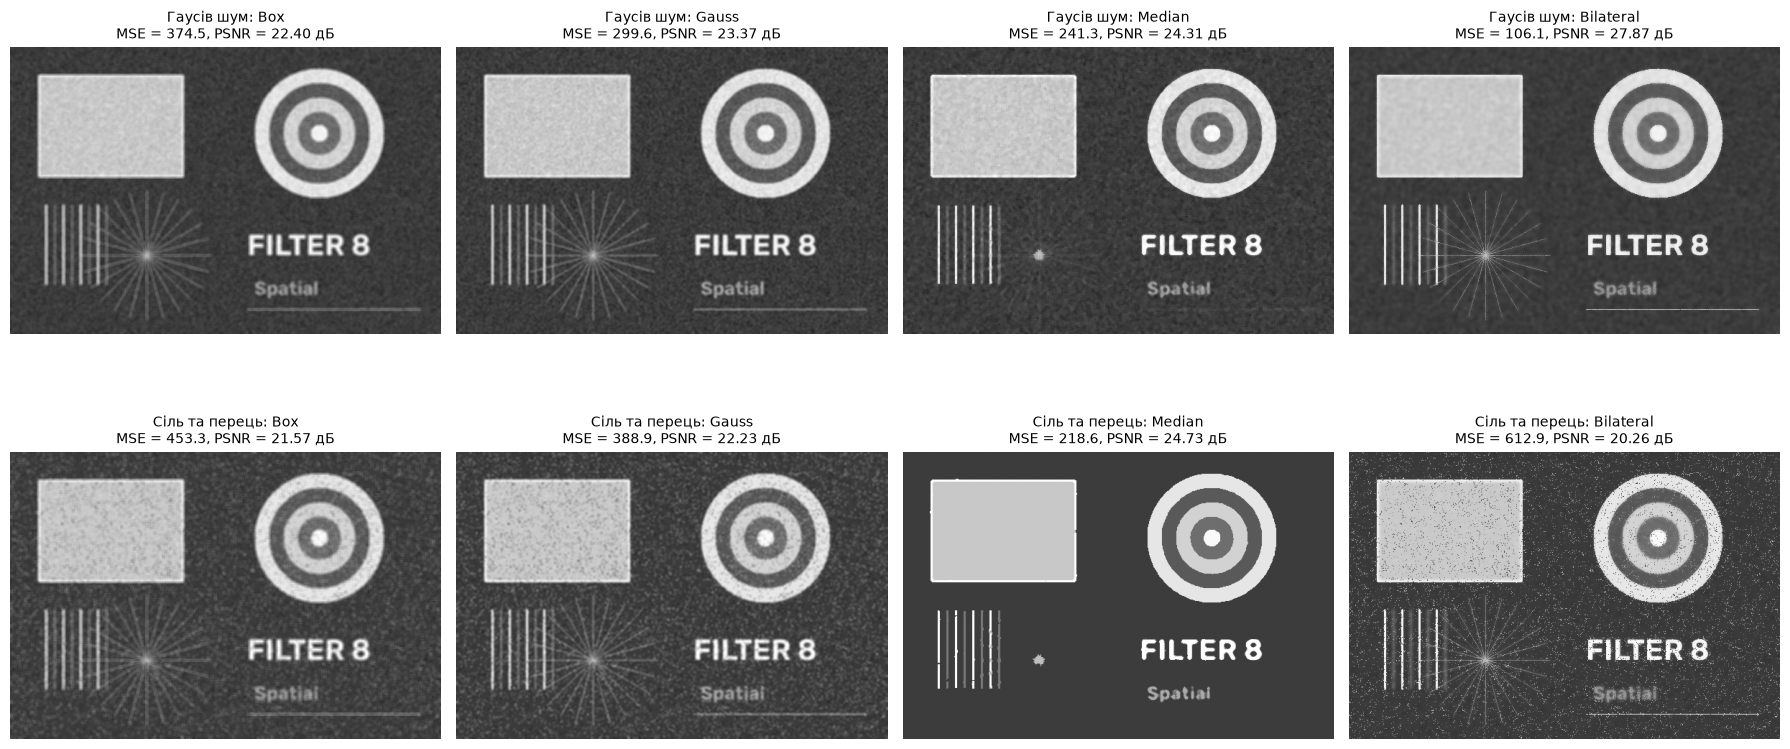

In [3]:
def apply_filters(noisy):
    """Повертає словник відфільтрованих зображень для одного зашумленого кадру."""
    return {
        "Box": cv2.blur(noisy, (K_BOX, K_BOX)),
        "Gauss": cv2.GaussianBlur(noisy, (K_GAUSS, K_GAUSS), SIGMA),
        "Median": cv2.medianBlur(noisy, K_MED),
        "Bilateral": cv2.bilateralFilter(noisy, BIL_D, BIL_SC, BIL_SS),
    }


results = {"Гаусів шум": apply_filters(noisy_g), "Сіль та перець": apply_filters(noisy_sp)}
noisy_by_type = {"Гаусів шум": noisy_g, "Сіль та перець": noisy_sp}

# перевірка: Box-фільтр cv2 збігається зі згорткою ядром з однаковими вагами в scipy.ndimage
box_kernel = np.full((K_BOX, K_BOX), 1.0 / K_BOX ** 2)
box_nd = ndimage.convolve(noisy_g.astype(np.float64), box_kernel, mode='mirror')
diff_box = np.abs(box_nd - results["Гаусів шум"]["Box"]).max()
# для несиметричного ядра згортка та кореляція дають різні результати
asym = np.array([[0, 0, 0], [1, 2, 4], [0, 0, 0]], dtype=np.float64) / 7
conv = ndimage.convolve(reference.astype(np.float64), asym, mode='mirror')
corr = ndimage.correlate(reference.astype(np.float64), asym, mode='mirror')
print("\n--- ПЕРЕВІРКА ЗГОРТКИ ТА КОРЕЛЯЦІЇ ---")
print(f"max|cv2.blur - ndimage.convolve| для Box 5x5 = {diff_box:.2f} рівня (різниця від округлення до uint8)")
print(f"Для несиметричного ядра max|згортка - кореляція| = {np.abs(conv - corr).max():.2f}; "
      f"для симетричних ядер Box та Gauss вони збігаються")

print("\n--- ТАБЛИЦЯ MSE ТА PSNR ---")
print(f"{'Фільтр':<22}{'Гаус: MSE':>12}{'Гаус: PSNR, дБ':>16}{'S&P: MSE':>12}{'S&P: PSNR, дБ':>16}")
print(f"{'Без обробки':<22}{mse_g:>12.2f}{psnr_g:>16.2f}{mse_sp:>12.2f}{psnr_sp:>16.2f}")
metrics = {}
for name in ["Box", "Gauss", "Median", "Bilateral"]:
    mg, pg = calculate_metrics(reference, results["Гаусів шум"][name])
    ms, ps = calculate_metrics(reference, results["Сіль та перець"][name])
    metrics[name] = (mg, pg, ms, ps)
    label = {"Box": f"Box ({K_BOX}x{K_BOX})", "Gauss": f"Gauss ({K_GAUSS}x{K_GAUSS}, s={SIGMA})",
             "Median": f"Median ({K_MED})", "Bilateral": f"Bilateral (d={BIL_D})"}[name]
    print(f"{label:<22}{mg:>12.2f}{pg:>16.2f}{ms:>12.2f}{ps:>16.2f}")
best_g = min(metrics, key=lambda k: metrics[k][0])
best_sp = min(metrics, key=lambda k: metrics[k][2])
print(f"Найкращий фільтр для гаусового шуму: {best_g}; для імпульсного шуму: {best_sp}")

fig, axes = plt.subplots(2, 4, figsize=(18, 9))
for i, (noise_name, filt) in enumerate(results.items()):
    for j, (fname, out) in enumerate(filt.items()):
        mse_v, psnr_v = calculate_metrics(reference, out)
        axes[i, j].imshow(out, cmap='gray', vmin=0, vmax=255)
        axes[i, j].set_title(f"{noise_name}: {fname}\nMSE = {mse_v:.1f}, PSNR = {psnr_v:.2f} дБ", fontsize=10)
        axes[i, j].axis('off')
plt.tight_layout()
plt.savefig("figures/smoothing_filters_results.png", dpi=300)
plt.show()

**Перевірка згортки та кореляції:** для Box $5 \times 5$ `cv2.blur` відрізняється від `scipy.ndimage.convolve` не більше ніж на 0.48 рівня (різниця округлення до `uint8`). Для несиметричного ядра максимальна різниця між згорткою та кореляцією дорівнює 83.57 рівнів, а для симетричних ядер (Box, Гаус) вони збігаються.

**Таблиця MSE та PSNR:**

| Фільтр | Гаус: MSE | Гаус: PSNR, дБ | S&P: MSE | S&P: PSNR, дБ |
|---|---|---|---|---|
| Без обробки | 601.43 | 20.34 | 1691.60 | 15.85 |
| Box (5×5) | 374.40 | 22.40 | 452.92 | 21.57 |
| Gauss (5×5, σ = 1.5) | 299.59 | 23.37 | 388.74 | 22.23 |
| Median (5) | 241.93 | 24.29 | 217.45 | 24.76 |
| Bilateral (d = 9) | 106.11 | 27.87 | 612.56 | 20.26 |

Для гаусового шуму найкращим виявився білатеральний фільтр (MSE 106.11, виграш 7.5 дБ), він згладжує плоскі області та зберігає межі. Медіанний фільтр найкращий для імпульсного шуму (MSE 217.45, 24.76 дБ): викиди займають менше половини околиці й відкидаються як крайні рангові значення. Box і Gauss розмивають імпульси разом з межами, а білатеральний фільтр для імпульсів малоефективний (MSE 612.56): імпульс різко відрізняється за яскравістю від сусідів, тому фотометрична вага сусідніх пікселів щодо нього близька до нуля: викид не усереднюється і залишається на місці. На зображеннях видно, що медіанний фільтр стер тонкі промені (їхня ширина — 1 піксель) і спотворив вузькі штрихи, тоді як лінійні фільтри їх розмили, але не прибрали.

### Блок 4. Підвищення різкості оператором Лапласа


--- ПІДВИЩЕННЯ РІЗКОСТІ (k = 0.60) ---
Сума коефіцієнтів ядра Лапласа = 0 (однорідні ділянки не змінюються)
Еталон                                               MSE =     0.00, PSNR =    inf дБ
Еталон після підвищення різкості                     MSE =   335.11, PSNR =  22.88 дБ
Гаусів шум, фільтр Bilateral                         MSE =   106.09, PSNR =  27.87 дБ
Те саме після підвищення різкості                    MSE =   519.51, PSNR =  20.97 дБ
Гаусів шум без фільтрації, з підвищенням різкості    MSE =  8700.41, PSNR =   8.74 дБ
Максимальний градієнт Собеля: еталон 872, після підвищення різкості 1140


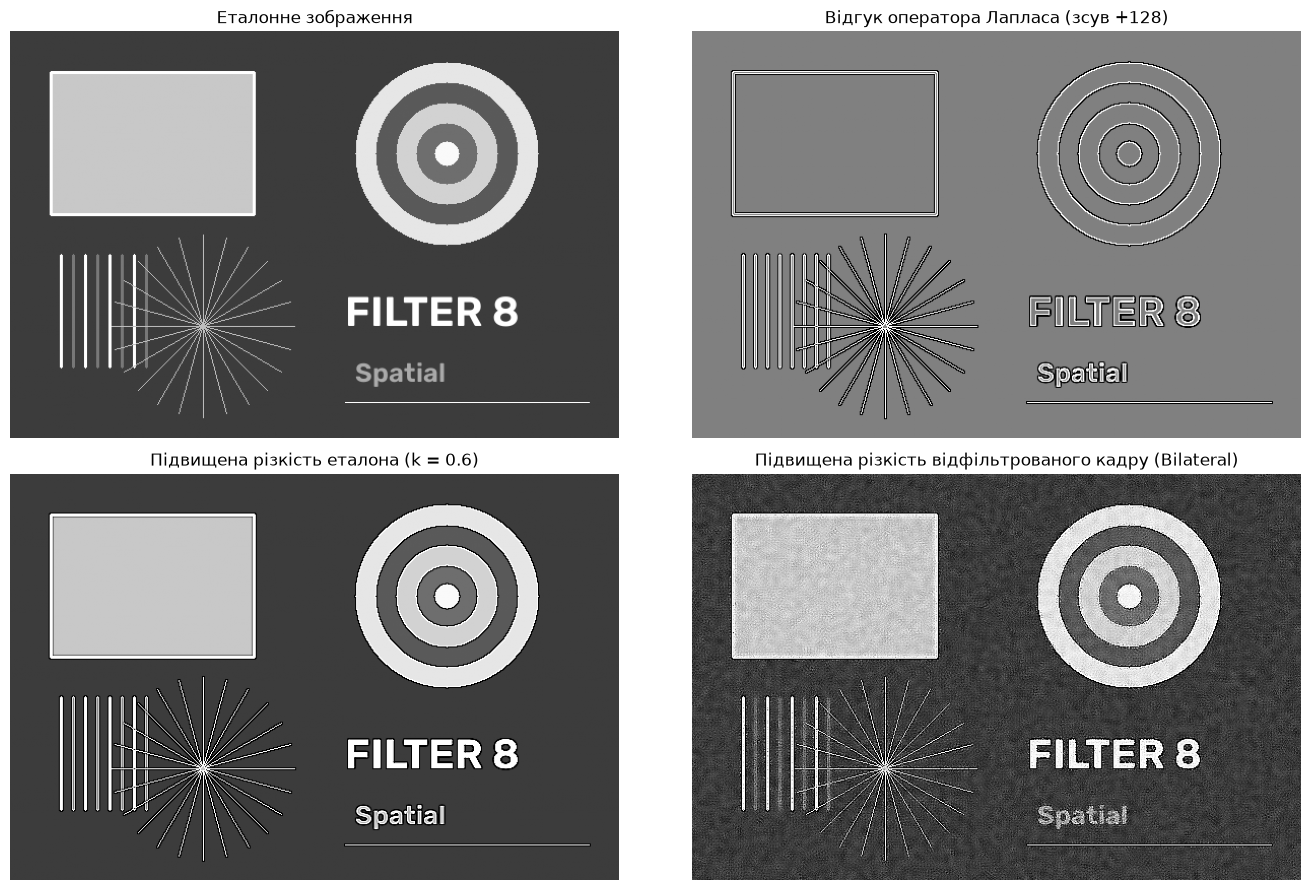


Моделювання завершено. Графіки збережено в 'figures/'.


In [4]:
laplace_kernel = np.array([[-1, -1, -1],
                           [-1, 8, -1],
                           [-1, -1, -1]], dtype=np.float32)


def sharpen_laplacian(image, k=K_SHARP):
    """I_sharp = I + k * (Лапласіан I), обчислення у float32 з відсіканням."""
    f = image.astype(np.float32)
    lap = cv2.filter2D(f, -1, laplace_kernel, borderType=cv2.BORDER_REFLECT_101)
    return np.clip(f + k * lap, 0, 255).astype(np.uint8), lap


# для відновлення беремо найкращий фільтр для гаусового шуму
filtered = results["Гаусів шум"][best_g]
sharp_ref, lap_ref = sharpen_laplacian(reference)
sharp_filt, _ = sharpen_laplacian(filtered)
sharp_noisy, _ = sharpen_laplacian(noisy_g)

print("\n--- ПІДВИЩЕННЯ РІЗКОСТІ (k = {:.2f}) ---".format(K_SHARP))
print(f"Сума коефіцієнтів ядра Лапласа = {laplace_kernel.sum():.0f} (однорідні ділянки не змінюються)")
for name, a in [("Еталон", reference), ("Еталон після підвищення різкості", sharp_ref),
                (f"Гаусів шум, фільтр {best_g}", filtered),
                (f"Те саме після підвищення різкості", sharp_filt),
                ("Гаусів шум без фільтрації, з підвищенням різкості", sharp_noisy)]:
    m, p = calculate_metrics(reference, a)
    print(f"{name:<52} MSE = {m:>8.2f}, PSNR = {p:>6.2f} дБ")
grad = lambda a: np.hypot(cv2.Sobel(a, cv2.CV_32F, 1, 0), cv2.Sobel(a, cv2.CV_32F, 0, 1)).max()
print(f"Максимальний градієнт Собеля: еталон {grad(reference):.0f}, після підвищення різкості {grad(sharp_ref):.0f}")

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
axes[0, 0].imshow(reference, cmap='gray', vmin=0, vmax=255)
axes[0, 0].set_title("Еталонне зображення")
axes[0, 1].imshow(np.clip(lap_ref + 128, 0, 255), cmap='gray', vmin=0, vmax=255)
axes[0, 1].set_title("Відгук оператора Лапласа (зсув +128)")
axes[1, 0].imshow(sharp_ref, cmap='gray', vmin=0, vmax=255)
axes[1, 0].set_title(f"Підвищена різкість еталона (k = {K_SHARP})")
axes[1, 1].imshow(sharp_filt, cmap='gray', vmin=0, vmax=255)
axes[1, 1].set_title(f"Підвищена різкість відфільтрованого кадру ({best_g})")
for ax in axes.ravel():
    ax.axis('off')
plt.tight_layout()
plt.savefig("figures/sharpening_laplacian.png", dpi=300)
plt.show()

print("\nМоделювання завершено. Графіки збережено в 'figures/'.")

**Підвищення різкості** ($k_{sharp} = 0.60$; для відновлення береться білатеральний фільтр):

| Зображення | MSE | PSNR, дБ |
|---|---|---|
| Гаусів шум, білатеральний фільтр | 106.11 | 27.87 |
| Те саме після підвищення різкості | 518.84 | 20.98 |
| Гаусів шум без фільтрації, з підвищенням різкості | 8701.75 | 8.73 |
| Еталон після підвищення різкості (відхилення від еталона) | 334.37 | 22.89 |

Максимальний градієнт Собеля зріс з 872 (еталон) до 1140 (після підвищення різкості): межі стали різкішими. Метрики MSE та PSNR відносно вихідного еталона для підвищення різкості не є показником покращення: оператор навмисно змінює зображення (створює викиди біля меж), тому MSE зростає навіть для чистого кадру (334.37). Головний результат: підвищення різкості без попереднього шумозаглушення підсилює шум приблизно в 17 разів (MSE 8701.75 проти 518.84 після фільтрації), бо лапласіан є диференціальним оператором і найсильніше реагує на високочастотні складові, тобто на шум.

## 5. Висновки

1. Для гаусового шуму ($\sigma_g = 25$) найкращий результат дав білатеральний фільтр ($d = 9$, $\sigma_c = \sigma_s = 80$): MSE зменшилось з 601.43 до 106.11, PSNR зросло з 20.34 до 27.87 дБ. Далі за якістю йдуть медіанний (241.93), Гаусів (299.59) та Box (374.40) фільтри.

2. Для імпульсного шуму ($p_{sp} = 0.08$) найкращим є медіанний фільтр (MSE 217.45, PSNR 24.76 дБ проти 15.85 дБ без обробки): це нелінійний ранговий фільтр, і викиди не потрапляють до медіани. Лінійні Box (452.92) та Gauss (388.74) лише розподіляють імпульс по околиці, а білатеральний фільтр практично не прибирає імпульсів (612.56).

3. Лінійні фільтри зменшують дисперсію шуму в плоских областях у 25 (Box) і приблизно в 20 разів (Gauss), але розмивають межі та тонкі лінії; Гаусів фільтр дає кращу якість за Box при тому самому розмірі ядра (299.59 проти 374.40). Недолік медіанного фільтра — він стирає лінії завтовшки в 1 піксель, що видно на променях еталонної сцени.

4. Оператор Лапласа з $k = 0.60$ збільшує максимальний градієнт на межах з 872 до 1140, але підсилює й шум: різкість без попередньої фільтрації дає MSE 8701.75, а після білатеральної фільтрації 518.84. Тому підвищення різкості потрібно виконувати після шумозаглушення.

5. Вибір фільтра залежить від типу шуму: гаусів шум — білатеральний або Гаусів фільтр, імпульсний — медіанний. Для змішаного шуму можна спробувати послідовно застосувати медіанний, а потім білатеральний фільтри (у цій роботі це не перевірялося).

## Відповідь на контрольні питання

**1. У чому полягає математична та алгоритмічна різниця між операціями двовимірної просторової згортки та кореляції при обробці зображень?**

* **Математична різниця:**
* **Кореляція** ($f \star w$) обчислює суму попіксельних добутків ваг ядра фільтра $w(s, t)$ та значень пікселів зображення $f(x + s, y + t)$ без зміни орієнтації ядра:

$$(f \star w)(x, y) = \sum_{s=-a}^{a} \sum_{t=-b}^{b} w(s, t) \, f(x + s, y + t)$$


* **Згортка** ($f * w$) виконує попереднє дзеркальне відображення (поворот на $180^\circ$) ядра фільтра за обома просторовими координатами перед обчисленням суми добутків:

$$(f * w)(x, y) = \sum_{s=-a}^{a} \sum_{t=-b}^{b} w(s, t) \, f(x - s, y - t)$$




* **Алгоритмічна та функціональна різниця:**
* Алгоритмічно згортка містить додатковий крок інвертування індексів ядра (повороту маски на $180^\circ$) перед проходом по зображенню.
* Для **симетричних ядер** (усереднюючий, Гаусівський фільтри, Лапласіан) $w(s, t) = w(-s, -t)$, тому результати згортки та кореляції повністю збігаються.
* Для **несиметричних ядер** результати відрізняються: **згортка** задовольняє комутативний та асоціативний закони (що є основою аналізу лінійних інваріантних до зсуву систем і теореми про згортку в частотній області), тоді як **кореляція** безпосередньо застосовується для пошуку за шаблоном (template matching), оцінюючи ступінь подібності еталонної маски до фрагмента зображення.



---

**2. Яким чином вибір розміру ядра $K \times K$ усереднюючого та Гаусового фільтрів впливає на ступінь придушення шуму та чіткість дрібних деталей зображення?**

* **Вплив на ступінь придушення шуму:** Збільшення розміру вікна $K \times K$ (наприклад, з $3 \times 3$ до $7 \times 7$ або $11 \times 11$) залучає до обчислення більше сусідніх пікселів ($K^2$). Для некорельованого флуктуаційного (Гаусового) шуму з дисперсією $\sigma_n^2$ просте усереднення по $K^2$ пікселях зменшує дисперсію шуму в $K^2$ разів (а середньоквадратичне відхилення — у $K$ разів). Відповідно, чим більше $K$, тим сильніше пригнічується шум.
* **Вплив на чіткість дрібних деталей:** Збільшення $K$ знижує ефективну частоту зрізу фільтра низьких частот. Це призводить до сильнішого просторового розмиття різких переходів яскравості (контурів об'єктів, тонких ліній, дрібних текстур), а об'єкти, менші за розмір вікна $K$, можуть повністю зникати, зливаючись із фоном.
* **Відмінність між усереднюючим і Гаусовим фільтрами:** В усереднюючому фільтрі (Box) усі $K^2$ пікселів мають однакову вагу $1/K^2$, тому при великих $K$ виникає сильне розмиття та блокові артефакти. У Гаусовому фільтрі ваги спадають від центра до країв за законом Гауса, надаючи центральному пікселю найбільший пріоритет — завдяки цьому за того самого розміру $K$ Гаусівський фільтр краще зберігає контури й не створює блокових спотворень (проте зі збільшенням $K$ та $\sigma$ розмиття також зростає).

---

**3. Чому лінійні фільтри низьких частот (Box, Gauss) є малоефективними для усунення імпульсного шуму типу «сіль та перець»?**

* **Природа імпульсного шуму:** Шум типу «сіль та перець» проявляється у вигляді поодиноких ізольованих пікселів із екстремальними значеннями яскравості ($0$ — чорні точки «перець» і $255$ — білі точки «сіль»), які різко контрастують із навколишнім фоном.
* **Причина неефективності лінійних фільтрів:** Лінійні фільтри (Box, Gauss) обчислюють **зважене середнє арифметичне** всіх пікселів у межах вікна $K \times K$. Оскільки аномальний імпульсний піксель ($0$ або $255$) має величезне відхилення від істинного значення, він суттєво зміщує середнє арифметичне всього околу. Замість того щоб видалити шумовий викид, лінійний фільтр **«розмазує» енергію імпульсу на всі сусідні пікселі** в межах вікна, перетворюючи поодиноку яскраву чи темну точку на розмиту пляму та одночасно погіршуючи різкість меж по всьому зображенню.

---

**4. Опишіть принцип роботи нелінійного медіанного фільтра. Чому він належить до класу порядкових (рангових) статистичних фільтрів?**

* **Принцип роботи медіанного фільтра:** Для кожного пікселя зображення виділяється квадратний (або іншої форми) окіл розміром $K \times K$, що містить $N = K^2$ пікселів. Усі значення яскравості в цьому вікні впорядковуються за зростанням (або спаданням) у варіаційний ряд, після чого центральний піксель замінюється на **медіану** — значення, яке стоїть точно посередині відсортованого списку (на позиції $\frac{N + 1}{2}$ для непарного $N$).
* **Чому належить до порядкових (рангових) статистичних фільтрів:** Рангові фільтри не виконують лінійного множення пікселів на вагові коефіцієнти та їх підсумовування, а ґрунтуються на **впорядкуванні (ранжуванні) значень яскравості** в околі та виборі елемента з певним порядковим номером (рангом) — для медіанного фільтра це $50$-й процентиль (середній ранг). Оскільки імпульсні завади ($0$ та $255$) є екстремальними значеннями, при сортуванні вони завжди потрапляють на крайні позиції ряду і повністю відкидаються при виборі середнього елемента, що дозволяє видаляти шум «сіль та перець» без розмиття контурів.

---

**5. За рахунок якого механізму білатеральний фільтр здатний одночасно ефективно згладжувати флуктуаційний шум на однорідних ділянках та повністю зберігати високу різкість границь об'єктів?**

Білатеральний фільтр є нелінійним згладжуючим фільтром, у якому ваговий коефіцієнт кожного сусіднього пікселя $q$ відносно центрального пікселя $p$ визначається як **добуток двох функцій Гауса** — просторової та яскравісної (фотометричної):


$$I_{\text{filtered}}(p) = \frac{1}{W_p} \sum_{q \in \Omega} I(q) \, G_{\sigma_s}(\Vert{}p - q\Vert{}) \, G_{\sigma_r}(\vert{}I(p) - I(q)\vert{})$$

* **Механізм дії на однорідних ділянках:** Сусідні пікселі в межах однієї області мають близькі значення яскравості ($\vert{}I(p) - I(q)\vert{}$ не перевищує амплітуду шуму), тому фотометричний множник $G_{\sigma_r}(\vert{}I(p) - I(q)\vert{}) \approx 1$. У цьому режимі білатеральний фільтр працює як звичайний просторовий фільтр Гауса $G_{\sigma_s}$, ефективно усереднюючи та пригнічуючи флуктуаційний шум.
* **Механізм збереження різкості на границях об'єктів:** На контурі об'єкта яскравість пікселя $q$ по інший бік межі різко відрізняється від $I(p)$ ($\vert{}I(p) - I(q)\vert{} \gg \sigma_r$). Через це яскравісний множник $G_{\sigma_r}(\vert{}I(p) - I(q)\vert{})$ прямує до нуля, фактично **виключаючи пікселі з протилежного боку межі** з процесу усереднення. Згладжування відбувається лише вздовж контуру серед пікселів одного об'єкта, завдяки чому висока різкість границь повністю зберігається.

---

**6. Які властивості має дискретний оператор Лапласа, і чому ядро Лапласіана обов'язково містить як додатні, так і від'ємні коефіцієнти?**

* **Основні властивості дискретного оператора Лапласа:**
* **Диференціальний оператор другого порядку:** Апроксимує суму других частинних похідних $\nabla^2 f = \frac{\partial^2 f}{\partial x^2} + \frac{\partial^2 f}{\partial y^2}$ за допомогою скінченних різниць.
* **Ізотропність (обертальна інваріантність):** На відміну від градієнтних операторів першого порядку, Лапласіан є скалярним оператором, інваріантним до повороту зображення (на кути, кратні $90^\circ$ для 4-зв'язного ядра та $45^\circ$ для 8-зв'язного ядра), тобто однаково виділяє перепади яскравості в усіх напрямках.
* **Нульовий відгук на однорідних ділянках і лінійних градієнтах:** Дає нуль на областях сталої яскравості та ділянках із постійним нахилом яскравості, формуючи подвійний відгук із переходом через нуль (zero-crossing) на ступінчастих межах та підкреслюючи тонкі лінії й ізольовані точки.
* **Висока чутливість до шуму:** Оскільки друга похідна підсилює високочастотні складові пропорційно квадрату частоти, оператор сильно реагує на шум (тому зазвичай застосовується після згладжування Гаусом у вигляді LoG — Laplacian of Gaussian).


* **Чому ядро Лапласіана обов'язково містить як додатні, так і від'ємні коефіцієнти:** Оператор диференціювання вимірює локальну зміну (кривизну) поля яскравості й на будь-якій ділянці постійної яскравості $f(x, y) = C = \text{const}$ повинен давати **суворо нульовий результат**:

$$\sum_{s, t} w(s, t) \cdot C = C \sum_{s, t} w(s, t) = 0 \implies \sum_{s, t} w(s, t) = 0$$



Оскільки ядро не є нульовим, умова рівності суми всіх вагових коефіцієнтів нулю може виконуватися лише тоді, коли додатні коефіцієнти врівноважуються від'ємними (наприклад, центральний елемент $-4$ або $-8$ та сусідні елементи $+1$, або навпаки).

---

**7. Що показують метрики $\text{MSE}$ та $\text{PSNR}$, і за якої умови реставрацію зображення можна вважати якісною?**

* **Що показує $\text{MSE}$ (Mean Squared Error — середньоквадратична похибка):** Характеризує середній квадрат попіксельної різниці яскравостей між еталонним (вихідним) зображенням $I$ та реставрованим (обробленим) зображенням $\hat{I}$ розміром $M \times N$:

$$\text{MSE} = \frac{1}{MN} \sum_{y=0}^{M-1} \sum_{x=0}^{N-1} \left[I(y, x) - \hat{I}(y, x)\right]^2$$



Метрика відображає середню енергію спотворень: чим ближче $\text{MSE}$ до нуля, тим менше відновлене зображення відрізняється від оригіналу.
* **Що показує $\text{PSNR}$ (Peak Signal-to-Noise Ratio — пікове відношення сигнал/шум):** Відображає логарифмічне відношення (у децибелах, дБ) між максимально можливою потужністю корисного сигналу ($\text{MAX}_I^2$, де для 8-бітного зображення $\text{MAX}_I = 255$) та потужністю похибки реставрації ($\text{MSE}$):

$$\text{PSNR} = 10 \log_{10} \left(\frac{\text{MAX}_I^2}{\text{MSE}}\right) = 20 \log_{10} \left(\frac{\text{MAX}_I}{\sqrt{\text{MSE}}}\right)$$



На відміну від $\text{MSE}$, метрика $\text{PSNR}$ є нормованою відносно розрядності зображення; вище значення $\text{PSNR}$ свідчить про вищу точність відновлення.
* **Умова якісної реставрації зображення:**
* Кількісно реставрація вважається якісною при мінімальному значенні $\text{MSE} \to 0$ та високому значенні $\text{PSNR}$ — для 8-бітних зображень якісним вважається відновлення за умови **$\text{PSNR} \ge 30\text{–}40\text{ дБ}$** (при $\text{PSNR} > 40\text{ дБ}$ спотворення практично непомітні для людського ока, а при повній ідентичності $\text{MSE} = 0$ і $\text{PSNR} \to \infty$).
* Оскільки $\text{MSE}$ та $\text{PSNR}$ оцінюють лише попіксельну енергетичну розбіжність і не враховують просторову структуру сцени, умовою повноцінної якісної реставрації є також збереження різкості контурів і текстур без надмірного розмиття (що додатково контролюється структурними метриками, зокрема $\text{SSIM}$).